# 03 · Classificador de sentenças

- **Amostra:** 3.954 sentenças, de `scripts/amostra.py`.
- **Rótulos:** anotador A, um subagente LLM seguindo o guia v2. O anotador B rotulou 300 sentenças do teste para medir concordância.
- **Modelos:** regex, TF-IDF com regressão logística e BERTimbau, de `scripts/modelos.py` e `scripts/bertimbau.py`.
- **Avaliação:** no teste fixo, separado **por pessoa**.

> As métricas medem a concordância com o anotador A (um LLM), não com uma verdade humana.

In [1]:
import json, sys
sys.path.insert(0, '../scripts')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
LAB = '../data/labels/'
met = json.load(open(LAB + 'metricas.json'))
conc = json.load(open(LAB + 'concordancia_v2.json'))
vaz = json.load(open(LAB + 'vazamento_genero.json'))
R = met['rotulos']
print('treino', met['n_treino'], '| teste', met['n_teste'])

treino 3332 | teste 622


## Rótulos na amostra

As contagens são brutas, na amostra estratificada. Elas **não** estimam a população: para isso é preciso usar a coluna `peso`.

In [2]:
am = pd.read_csv(LAB + 'amostra_v2.csv').merge(pd.read_csv(LAB + 'rotulos_anotador_a.csv').rename(columns={'id': 'sid'}), on='sid')
t = pd.crosstab(am.rotulo, am.sexo).reindex(R).fillna(0).astype(int)
t['total'] = t.sum(axis=1)
t

sexo,F,M,total
rotulo,,,
CAR,869,751,1620
FAM_ID,36,16,52
FAM_DET,230,342,572
FAM_ORIG,84,181,265
FAM_CAP,60,97,157
APAR,16,2,18
GEN,132,6,138
OUTRO,547,585,1132


## Concordância entre anotadores (guia v2)

In [3]:
print(f"κ A×B = {conc['kappa']} (n={conc['n']}); concordância bruta {conc['concordancia']:.0%}; κ do piloto (v1) = {conc['kappa_v1_piloto']}")
pd.Series(conc['kappa_por_rotulo'], name='κ por rótulo (um contra o resto)').to_frame()

κ A×B = 0.777 (n=300); concordância bruta 84%; κ do piloto (v1) = 0.63


,κ por rótulo (um contra o resto)
CAR,0.783
FAM_ID,0.921
FAM_DET,0.873
FAM_ORIG,0.788
FAM_CAP,0.624
APAR,NaN
GEN,1.000
OUTRO,0.672


## Vazamento de gênero após o mascaramento

In [4]:
pd.Series(vaz['auc'], name='AUC prevendo sexo=F').to_frame()

,AUC prevendo sexo=F
texto_so_nome,0.810
texto_mascarado,0.801


## Modelos no teste fixo

In [5]:
linhas = {m: {'macro-F1': v['macro_f1'], 'acurácia': v['acuracia'], 'κ vs A': v['kappa']} for m, v in met['modelos'].items()}
b = met.get('anotador_b_vs_a')
if b: linhas[f"anotador B (LLM, n={b['n']})"] = {'macro-F1': b['macro_f1'], 'acurácia': b['acuracia'], 'κ vs A': b['kappa']}
pd.DataFrame(linhas).T

,macro-F1,acurácia,κ vs A
bertimbau,0.698,0.812,0.742
regex,0.339,0.516,0.335
tfidf_logreg,0.503,0.685,0.562
"anotador B (LLM, n=300)",0.736,0.840,0.777


,bertimbau,regex,tfidf_logreg,suporte no teste
CAR,0.882,0.662,0.767,248
FAM_ID,0.364,0.000,0.143,9
FAM_DET,0.826,0.570,0.724,106
FAM_ORIG,0.611,0.433,0.472,38
FAM_CAP,0.604,0.000,0.450,25
APAR,0.667,0.154,0.000,2
GEN,0.840,0.894,0.857,23
OUTRO,0.788,0.000,0.614,171


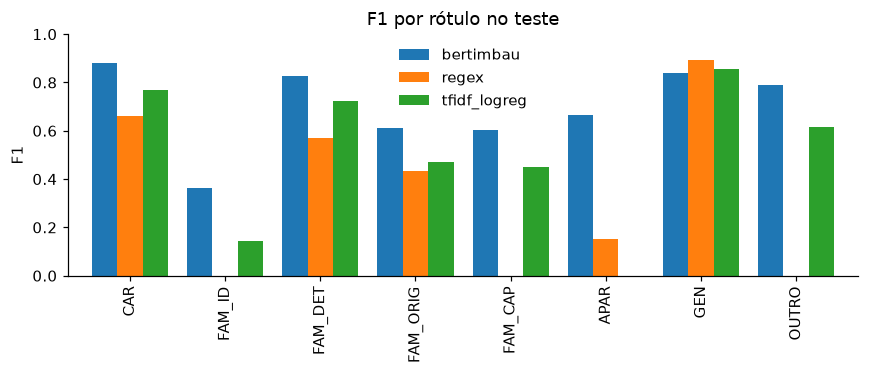

In [6]:
f1 = pd.DataFrame({m: v['f1_por_rotulo'] for m, v in met['modelos'].items()})
f1['suporte no teste'] = pd.Series(next(iter(met['modelos'].values()))['suporte'])
display(f1)
ax = f1.drop(columns='suporte no teste').plot.bar(figsize=(8, 3.5), width=.8)
ax.set_ylabel('F1'); ax.set_ylim(0, 1); ax.set_title('F1 por rótulo no teste'); ax.legend(frameon=False)
plt.tight_layout()

## Matriz de confusão do melhor modelo

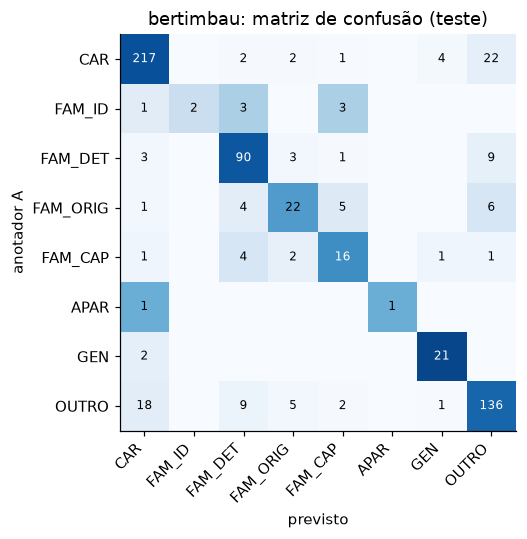

In [7]:
melhor = max(met['modelos'], key=lambda m: met['modelos'][m]['macro_f1'])
cm = np.array(met['modelos'][melhor]['matriz'])
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm / cm.sum(axis=1, keepdims=True).clip(1), cmap='Blues', vmin=0, vmax=1)
for i in range(len(R)):
    for j in range(len(R)):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='black' if cm[i, j] < cm[i].sum() * .6 else 'white')
ax.set_xticks(range(len(R)), R, rotation=45, ha='right'); ax.set_yticks(range(len(R)), R)
ax.set_xlabel('previsto'); ax.set_ylabel('anotador A'); ax.set_title(f'{melhor}: matriz de confusão (teste)')
plt.tight_layout()

In [8]:
import os
if os.path.exists(LAB + 'bertimbau_treino.json'):
    bt = json.load(open(LAB + 'bertimbau_treino.json'))
    print(bt['modelo'], bt['dispositivo'], bt['config'])
    display(pd.DataFrame(bt['historico']))

neuralmind/bert-base-portuguese-cased mps {'max_len': 128, 'batch': 16, 'epocas': 4, 'lr': 3e-05, 'warmup': 0.1, 'seed': 13}


,epoca,perda,val_macro_f1,segundos
0,1,1.4650,0.511,104
1,2,0.7758,0.712,99
2,3,0.4951,0.794,99
3,4,0.3458,0.769,100


## Guia v3 e reforço de FAM_ID

- **Guia v3:** acrescenta a regra 0 (frase de abertura) e o teste da cópula.
- **Reforço:** 350 sentenças de pessoas do treino.
- **Rótulos novos com a v3:** as sentenças de reforço, as de FAM_ID e FAM_DET do treino, as frases de abertura rotuladas OUTRO e o **teste fixo inteiro**.

Na comparação abaixo, todos os modelos são avaliados contra os **rótulos v3 do teste**, inclusive o BERTimbau treinado com a v2 (`bertimbau_treino_v2`).

In [9]:
m3 = json.load(open(LAB + 'metricas_v3.json'))
c3 = json.load(open(LAB + 'concordancia_v3.json'))
print(f"κ A×B: v1 {c3['kappa_v1_piloto']} → v2 {c3['kappa_v2']} → v3 {c3['kappa']} (n={c3['n']})")
t = pd.DataFrame({m: {'macro-F1': v['macro_f1'], 'κ vs A': v['kappa'], 'F1 FAM_ID': v['f1_por_rotulo']['FAM_ID']} for m, v in m3['modelos'].items()}).T
bs = pd.DataFrame(m3['bootstrap']).T
t.join(bs)

κ A×B: v1 0.63 → v2 0.777 → v3 0.873 (n=300)


,macro-F1,κ vs A,F1 FAM_ID,macro_f1_sem_APAR,macro_f1_sem_APAR_IC95,f1_FAM_ID,f1_FAM_ID_IC95
bertimbau,0.801,0.779,0.632,0.773,"[0.709, 0.825]",0.632,"[0.286, 0.857]"
bertimbau_treino_v2,0.740,0.710,0.333,0.703,"[0.634, 0.763]",0.333,"[0.0, 0.667]"
regex,0.349,0.371,0.000,NaN,NaN,NaN,NaN
tfidf_logreg,0.573,0.577,0.556,0.655,"[0.584, 0.71]",0.556,"[0.2, 0.8]"


In [10]:
f1v3 = pd.DataFrame({m: v['f1_por_rotulo'] for m, v in m3['modelos'].items()})
f1v3['suporte no teste'] = pd.Series(m3['modelos']['bertimbau']['suporte'])
f1v3

,bertimbau,bertimbau_treino_v2,regex,tfidf_logreg,suporte no teste
CAR,0.911,0.859,0.719,0.782,280
FAM_ID,0.632,0.333,0.000,0.556,10
FAM_DET,0.860,0.817,0.569,0.788,96
FAM_ORIG,0.700,0.714,0.463,0.592,36
FAM_CAP,0.655,0.667,0.000,0.444,26
APAR,1.000,1.000,0.167,0.000,1
GEN,0.870,0.816,0.870,0.870,22
OUTRO,0.781,0.714,0.000,0.553,151


## Observações

- APAR e FAM_ID são raros. Com os rótulos v3, há 77 casos de FAM_ID na amostra, 10 deles no teste, e 17 de APAR, 1 no teste. O F1 dessas classes tem intervalo largo (ver bootstrap). O macro-F1 sem APAR é a medida mais estável.
- O teto prático é a concordância entre anotadores: o anotador B atinge macro-F1 de cerca de 0,74 contra A. Um modelo acima disso estaria aprendendo os vieses do anotador A.
- O próximo passo é aplicar o melhor modelo às 1,1 milhão de sentenças e estimar as proporções por sexo, área e período, com os pesos e as correções de erro de classificação.